<div align="center">

# **Condensación de Bose-Einstein**

**Jerónimo López** <sup>[1]</sup>  
*Instituto de Física, Facultad de Ciencias Exactas y Naturales*  
*Universidad de Antioquia, Medellín, Colombia*

*Miniproyecto 2 - Curso de Física Estadística 2026-II*

*25 de Noviembre de 2026*

---
</div>

### <div align="center">**Resumen**</div>

<div align="justify">

<mark>Agregar Resumen</mark>

</div>

**Palabras clave:** <mark>Agregar Palabras Clave</mark>

---
</div>

<mark>
**Idea metodológica:** construir un espectro **discreto** de estados en una caja, sumar sus ocupaciones Bose–Einstein, determinar numéricamente el potencial químico imponiendo $\langle N\rangle=N$, y observar qué fracción se acumula en el nivel base. **La fórmula teórica del condensado NO se usa para generar los resultados:** aparece únicamente como comparación.
**Libro guía:** J. Restrepo Cárdenas, *Física Estadística: Teoría, Algoritmos y Problemas* (2026), §4.10, pp. 146–154, y §6.6, pp. 204–214.  
**Material de partida:** *Miniproyecto2_Nov2026.md* (7 de noviembre de 2026).
**Recorrido:** 1) física → 2) algoritmo → 3) verificación → 4) resultados → 5) pregunta original → 6) conclusiones y sustentación.
</mark>

## 1. Objetivo, hipótesis y preguntas

**Pregunta central.**

¿Es posible observar, mediante una simulación computacional, cómo una fracción macroscópica de las partículas comienza a ocupar el estado fundamental cuando la temperatura disminuye por debajo de una temperatura crítica?

**Objetivo general:** estudiar cómo emerge una población macroscópica del nivel fundamental en un gas ideal de bosones homogéneo en 3D y distinguir los resultados de tamaño finito del límite termodinámico.

**Hipótesis de trabajo:** a medida que disminuye $T$, los estados excitados pierden capacidad de alojar la población promedio requerida, el potencial químico se aproxima a la energía mínima y la ocupación del estado fundamental aumenta rápidamente.

**Preguntas del enunciado:** (i) distribución por energía; (ii) fracción condensada vs. temperatura; (iii) región de temperatura crítica; (iv) efecto de $N$ y densidad; (v) comparación con el límite termodinámico.

**Pregunta propia (exploración adicional):** ¿cómo cambia la acumulación de bosones en el estado fundamental si sustituimos las fronteras periódicas por paredes rígidas de la caja, manteniendo $N$, $V$ y $T$? Esta pregunta no está explícita en el listado del proyecto y se analiza **computacionalmente** con dos espectros discretos.

## 2. Modelo físico: qué representa y qué NO representa

Consideramos un gas ideal de N bosones de espín cero, no interactuantes, confinados en una caja cúbica de volumen $V=L^3$, que además se encuentran en equilibrio termodinámico a temperatura $T$. Esta elección permite estudiar la condensación de Bose–Einstein sin introducir degeneración adicional.

Consideremos para efectos de la simulación, a los bosones confinados en una caja tridimensional, donde las condiciones de frontera en las paredes de la misma, sean condiciones de frontera periódicas, i.e, la función de onda de las particulas confinadas cumple que $\psi(\vec{r} + \vec{L}) = \psi(\vec{r})$, donde $\vec{r} = (x,y,z)$. Dada las condiciones de forntera entonces el respectivo vector de onda descrito por cada particula y las respectivas energías estan dadas por las siguientes expresiones:

$$
\mathbf k=\frac{2\pi}{L}(k_x,k_y,k_z),\quad k_\alpha\in\mathbb Z,\qquad
\varepsilon_{\mathbf k}=E_L(k_x^2+k_y^2+k_z^2),\quad
E_L=\frac{2\pi^2\hbar^2}{mL^2}

\tag{1}
$$

Donde el estado fundamental de energía $\varepsilon_0$ corresponde al único vector $\mathbf k_0=(0,0,0)$, evaluada en $\varepsilon_0=0$, además debe contarse con la degeneración $g_s$ que de cuenta de múltiples estados cuánticos en el mismo nivel de energía $\varepsilon_i$.

En el caso de las partículas bosónicas, la ocupación media $\langle n_s\rangle$ para un estado $s$ siguen el modelo estadístico de Bose-Einstein (B-E):

$$
\langle n_s\rangle=\frac{1}{e^{\beta(\varepsilon_s-\mu)}-1},\quad
\beta=\frac{1}{k_BT}

\tag{2}
$$

Por tanto, el promedio de partículas que comparten un mismo nivel de energía con degeneración $g_s$ es $g_s\cdot \langle n_s\rangle$. Por lo anterior, la población del estado fundamental está dada por $g_0 \langle n_0\rangle$, donde $g_0 = 1$, con lo cuál se define $\langle n_0\rangle = N_0$. Se ajusta en la simulación, el potencial químico $\mu_T$ para que el número promedio total de partículas coincida siempre con el valor finito $N$ establecido por el usuario. El número total de bosones $N = N_0 + N_S$ reemplazando la ocupación media esta determinado de acuerdo a la siguiente expresión:

$$
N = \frac{1}{e^{\beta(\varepsilon_0 - \mu)}-1} + \sum_{s=1}^{S} \frac{g_s}{e^{\beta(\varepsilon_s - \mu)}-1}

\tag{3}
$$

Definamos las cantidades adimensionales $x=\beta (\varepsilon_0-\mu)$ y $a_s=\beta (\varepsilon_s-\varepsilon_0)$ para efectos de optimizar cálculos computacionales y evitar cantidades marginales.

$$
N = \underbrace{\frac{1}{e^x-1}}_{N_0} +
\underbrace{\sum_{s=1}^{S}\frac{g_s}{e^{a_s+x}-1}}_{N_{\mathrm{exc}}}
\tag{A}
$$

Para cada temperatura, tanto la población del estado fundamental $N_0$ como la de los estados excitados $N_{\mathrm{exc}}$ deben disminuir monótonamente con $x$, y por tanto $N$ es estrictamente decreciente, por lo que puede implementarse un algoritmo de busqueda de raíces en intervalos definidos usando `brentq`.

Posteriormente, con $x$ determinado se obtienen los porcentajes de ocupación $\frac{N_i}{N}$ así como el potencial químico respectivo $\mu_T$ a temperaturas $T$ determinadas.

Para la simulación se utiliza un diccionario `atoms_dict` que permite seleccionar diferentes especies atómicas y sus respectivas masas. Adicionalmente, se establecen el número de partículas $N$ y la densidad $n=N/V$ como parámetros del sistema.

Las temperaturas se expresan de forma reducida mediante $T/T_c$, donde $T_c$ es la temperatura crítica teórica.

Finalmente, para construir los niveles de energías se introduce un factor `FC` o factor de corte, que limita el número de los estados excitados incluidos en el cálculo. Este parámetro establece una energía máxima de referencia:

$$
\varepsilon_{\max}-\varepsilon_0 \approx
\mathrm{FC} (k_BT_{\max})
$$

donde $T_{\max}$ es la temperatura máxima considerada. De esta manera, se evita incluir una cantidad innecesaria de estados de alta energía cuya ocupación es muy pequeña.

In [28]:
# Dependencias e identidad del experimento. Ejecutar desde la primera celda.
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Importamos constantes físicas y funciones especiales de SciPy
from scipy.constants import hbar, Boltzmann as kB, atomic_mass, pi
from scipy.special import zeta  #Función zeta de Riemann
from scipy.optimize import brentq

#Establecemos un directorio para guardar las figuras generadas por el experimento.
FIG_DIR = Path('figuras')
FIG_DIR.mkdir(exist_ok=True)

# Configuración formal y global para todas las figuras.
plt.rcParams.update({
    'figure.figsize': (8.0, 5.0), 'figure.dpi': 125, 'savefig.dpi': 185,
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.labelsize': 10.5, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.20, 'grid.linestyle': '--',
    'legend.frameon': False, 'lines.linewidth': 2.0,
    'figure.constrained_layout.use': True,
})
PALETA = {'teoria':'#152a47','periodica':'#197a89','rigida':'#bc5c43',
          'baja':'#274c77','media':'#269183','alta':'#d17d37'}

def guardar(nombre):
    plt.savefig(FIG_DIR / nombre, bbox_inches='tight', facecolor='white')
    plt.show()

#Validación de dependencias y presentación de la identidad del experimento.
print('Validando dependencias...')
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy disponible')

Validando dependencias...
Python 3.13.18 | NumPy 2.4.6 | SciPy disponible


In [30]:
#Parámetros Globales de Configuración del Experimento

# Definición de átomos para el experimento y sus masas
atoms_dict = {
    'Rb-87': {'masa': 87.0 * atomic_mass},
    'Na-23': {'masa': 23.0 * atomic_mass},
    'Li-7': {'masa': 7.0 * atomic_mass},
}

# Selección del átomo
atom = 'Rb-87'

SEED = 12123203                                             # SEED para reproducibilidad
N_PRINCIPAL = 1000                                          # Partículas (promedio objetivo)
DENSIDAD_PRINCIPAL = 1.0e19                                 # m^-3 (ilustrativa)
V = N_PRINCIPAL / DENSIDAD_PRINCIPAL                        # m^3, volumen de la caja
L = V**(1/3)                                                # m, longitud de la caja
MASA = atoms_dict[atom]['masa']                             # kg, masa real de un átomo, en este caso de Rb-87
FACTOR_CORTE = 18.0                                         # Define el factor de corte para la energía máxima en unidades de k_B T_c.
TEMPERATURAS_REDUCIDAS = np.linspace(0.22, 1.80, 82)        # Temperaturas reducidas T/T_c, desde 0.22 hasta 1.80
ZETA_3_2 = float(zeta(1.5, 1.0))



print(f'Experimento de condensación de Bose-Einstein en un gas de {N_PRINCIPAL} átomos de {atom} en una caja cúbica de volumen {V:.2e} m³ (L = {L:.2e} m).')
print(f'| ζ(3/2) = {ZETA_3_2:.8f}\n| N = {N_PRINCIPAL}\n| densidad = {DENSIDAD_PRINCIPAL:.2e} m⁻³\n| V = {V:.2e} m³\n| L = {L:.2e} m\n| masa = {MASA:.2e} kg\n| corte = {FACTOR_CORTE}\n| temperaturas reducidas = {TEMPERATURAS_REDUCIDAS[0]:.2f} a {TEMPERATURAS_REDUCIDAS[-1]:.2f}')

Experimento de condensación de Bose-Einstein en un gas de 1000 átomos de Rb-87 en una caja cúbica de volumen 1.00e-16 m³ (L = 4.64e-06 m).
| ζ(3/2) = 2.61237535
| N = 1000
| densidad = 1.00e+19 m⁻³
| V = 1.00e-16 m³
| L = 4.64e-06 m
| masa = 1.44e-25 kg
| corte = 18.0
| temperaturas reducidas = 0.22 a 1.80


## 3. Algoritmo: estados discretos, degeneración y raíz de conservación

No se distribuyen partículas arbitrariamente entre estados cuánticos, sino que se calculan sus ocupaciones medias mediante la estadística de Bose–Einstein. Para ello, se realiza el siguiente procedimiento:

**1.** Se selecciona la especie atómica y se establecen el número de partículas $N$ y la densidad numérica $n=N/V$, a partir de los cuales se determina el volumen $V$ y la longitud $L$ de la caja cúbica.

**2.** Se construyen los vectores de onda permitidos $\mathbf{k}$ y se calculan sus respectivas energías $\varepsilon_{\mathbf{k}}$.

**3.** Para cada temperatura reducida $T/T_c$, se determina numéricamente $x$ hasta satisfacer la condición $N=N_0+N_{\mathrm{exc}}$.

**5.** Con el valor obtenido de $x$, se calculan las ocupaciones de los niveles energéticos, la fracción condensada $N_0/N$ y el potencial químico $\mu_T$.

**6.** Se repite el procedimiento para diferentes valores de densidad y número de partículas, con el propósito de analizar su influencia sobre la condensación.

Adicionalmente como se mencionaba anteriormente se introduce un factor de corte `FC` para limitar el número de estados excitados a considerar.

In [40]:
#Definimos una función auxiliar para calcular la temperatura crítica teórica
#de un gas de Bose-Einstein en función de la densidad y la masa del átomo.

def temperatura_critica_teorica(densidad, masa=MASA):
    return (2 * pi * hbar**2 / (masa * kB)) * (densidad / ZETA_3_2)**(2 / 3)



#---------------------------------------------------------------------------------------------------
#FUNCION PRINCIPAL: Cálculo de los niveles energéticos y sus degeneraciones para una caja 3D.
def niveles_caja(N, densidad, T_max, masa=MASA,
                  frontera='periodica', eta=FACTOR_CORTE):
    """
    Construye el espectro de en niveles discretos de la caja 3D.

    Retorna:
        delta_eps: energías relativas al estado fundamental
        g: degeneración de cada nivel

    Se incluyen estados con Δε <= eta*kB*T_max.
    """

    L = (N / densidad)**(1 / 3)
    E_max = eta * kB * T_max

    if frontera == 'periodica':
        # Calculamos los niveles de energía para una caja con condiciones de frontera periódicas.
        E_L = hbar**2 * (2*pi/L)**2 / (2*masa)

        #Establecemos el límite de energía máxima para los estados permitidos.
        limite = int(np.floor(E_max / E_L))

        kmax = int(np.ceil(np.sqrt(limite)))
        k = np.arange(-kmax, kmax + 1, dtype=np.int32)

        # Calculamos los cuadrados de las proyecciones de los vectores de onda
        s = (k[:, None, None]**2
             + k[None, :, None]**2
             + k[None, None, :]**2)

        #Descartamos los estados que superan el límite de energía máxima.
        indices = s[s <= limite]

    elif frontera == 'rigida':
        # Calculamos los niveles de energía para una caja con condiciones de frontera rígidas.
        E_L = hbar**2 * (pi/L)**2 / (2*masa)

        #Establecemos el límite de energía máxima para los estados permitidos.
        limite = int(np.floor(E_max / E_L))

        kmax = int(np.ceil(np.sqrt(limite + 3)))
        k = np.arange(1, kmax + 1, dtype=np.int32)

        s = (k[:, None, None]**2
             + k[None, :, None]**2
             + k[None, None, :]**2 - 3)

        #Descartamos los estados que superan el límite de energía máxima.
        indices = s[s <= limite]

    else:
        raise ValueError("frontera debe ser 'periodica' o 'rigida'")

    # Calculamos la degeneración de cada nivel de energía.
    degeneracion = np.bincount(
        indices.ravel(), minlength=limite + 1
    )

    #Identificamos los niveles de energía no vacíos y calculamos las energías y degeneraciones.
    no_vacias = np.flatnonzero(degeneracion)
    delta_eps = E_L * no_vacias.astype(float)
    g = degeneracion[no_vacias].astype(float)

    #Estamos considerando exclusivamente el caso para el estado fundamental,
    #que debe tener degeneración 1.
    if len(g) == 0 or g[0] != 1:
        raise RuntimeError('Esytado Fundamental con degeneración distinta de 1 o no encontrado')

    return delta_eps, g

#---------------------------------------------------------------------------------------------------

In [41]:
#FUNCION PRINCIPAL: Resolver la ligadura de ocupación de los niveles energéticos
#para un número promedio de partículas N y una temperatura T.
def resolver_ocupaciones(N, T, delta_eps, g):
    """
    Esta Función resuelve la ecuación de conservación del número promedio de partículas
    para un sistema de Bose-Einstein en una caja 3D, dado un número promedio de partículas N,
    una temperatura T, los niveles de energía delta_eps y sus degeneraciones g.
    """

    # Cantidad Adimensional a_s = β(ε_s - ε_0)
    a = delta_eps / (kB * T)

    def residuo(x):
        """Función Auxiliar para calcular el residuo del número promedio de partículas N"""
        with np.errstate(over='ignore', under='ignore'):
            return np.sum(g / np.expm1(a + x)) - N

    #Definimos los límites para la búsqueda de la raíz de la función residuo.
    x_bajo = 0.5 * np.log1p(1.0 / N)
    x_alto = 1.0

    #Si el residuo en el límite superior es positivo, duplicamos el límite superior hasta que sea negativo.
    #Con el fin de garantizar que la función residuo tenga un cambio de signo en el intervalo [x_bajo, x_alto].
    while residuo(x_alto) > 0:
        x_alto *= 2.0

    #Utilizamos el método de Brent para encontrar la raíz de la función residuo en el intervalo [x_bajo, x_alto].
    x = brentq(
        residuo, x_bajo, x_alto,
        xtol=1e-13, rtol=1e-13
    )

    #Calculamos el nivel de ocupación para cada estado energético utilizando la raíz encontrada.
    with np.errstate(over='ignore', under='ignore'):
        nivel = g / np.expm1(a + x)

    return {
        # Cantidad Adimensional x = -β(μ - ε_0)
        'x': x,
        # Nivel de ocupación de cada estado energético
        'nivel': nivel,
        # Número de partículas en el estado fundamental
        'N0': float(nivel[0]),
        # Número de partículas en los estados excitados
        'Nexc': float(nivel[1:].sum()),
        # Error de conservación del número promedio de partículas
        'error_conservacion': float(nivel.sum() - N)
    }

#---------------------------------------------------------------------------------------------------
#FUNCION PRINCIPAL: Barrido numérico para diferentes temperaturas de la fracción de condensado N0/N

def curva_temperatura(N, densidad, t_reducidas,
                      frontera='periodica', eta=FACTOR_CORTE):
    """
    Realiza el barrido numérico de la fracción de condensado N0/N, dado N
    las temperaturas reducidas t_reducidas = T/Tc, la densidad y el tipo de frontera.
    """

    Tc = temperatura_critica_teorica(densidad)
    temperaturas = np.asarray(t_reducidas) * Tc

    delta_eps, g = niveles_caja(
        N, densidad, float(np.max(temperaturas)),
        frontera=frontera, eta=eta
    )

    resultados = [
        resolver_ocupaciones(N, T, delta_eps, g)
        for T in temperaturas
    ]

    tabla = pd.DataFrame({
        'T_Tc': t_reducidas,
        'T_nK': temperaturas * 1e9,
        'N0_N': [r['N0']/N for r in resultados],
        'Nexc_N': [r['Nexc']/N for r in resultados],
        'error_N': [r['error_conservacion'] for r in resultados]
    })

    return tabla, (delta_eps, g)

#---------------------------------------------------------------------------------------------------

#Definimos una función auxiliar para calcular la fracción de condensado teórica N0/N para un BEC
def fraccion_teorica(T):
    """Calcula la fracción de condensado teórica N_0/N para un BEC"""
    T = np.asarray(T)
    return np.maximum(1 - np.power(T, 3/2), 0.0)


#Definimos una función auxiliar para calcular la temperatura de saturación de los estados excitados
def temperatura_saturacion_exc(N, densidad, delta_eps, g):
    """
    Se calcula la temperatura de saturación de los estados excitados,
    es decir, la temperatura a la cual Nexc = N, lo que implica que N_0 -> 0
    """
    Tc = temperatura_critica_teorica(densidad)

    #Se hallan los residuos de la capacidad de los estados excitados para encontrar la temperatura de saturación.
    def residuo_capacidad(T):
        a = delta_eps[1:] / (kB * T)
        with np.errstate(over='ignore', under='ignore'):
            return np.sum(g[1:] / np.expm1(a)) - N

    #Definamos los límites para la búsqueda de la raíz de la función residuo.
    bajo, alto = Tc * 1e-6, Tc

    #Si no hay cambio de signo en el intervalo [bajo, alto], duplicamos el límite superior
    while residuo_capacidad(alto) < 0:
        alto *= 2.0

    return brentq(
        residuo_capacidad, bajo, alto,
        xtol=1e-16, rtol=1e-12
    )
#---------------------------------------------------------------------------------------------------

Tc teórica = 85.728 nK
T saturación = 94.923 nK
T/Tc = 0.5 | N0/N = 0.7221
T/Tc = 1.0 | N0/N = 0.1716
T/Tc = 1.5 | N0/N = 0.0057


/tmp/ipykernel_1331/3922203070.py:104: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


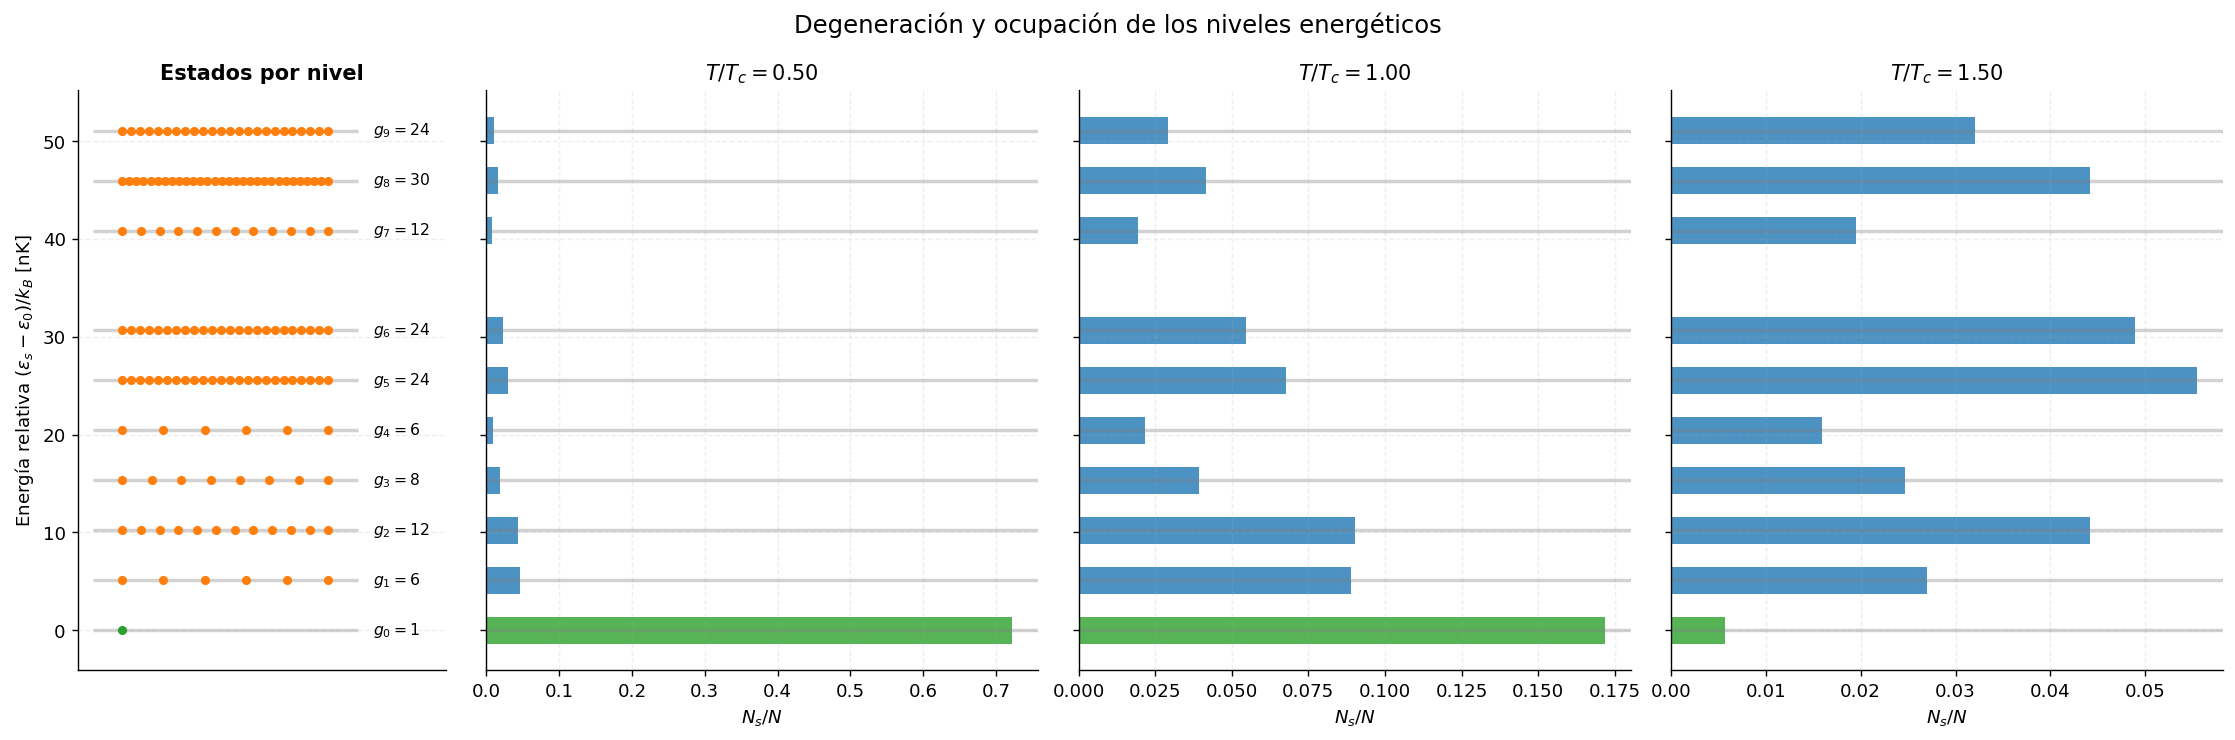

In [46]:
# Temperatura crítica teórica
Tc = temperatura_critica_teorica(DENSIDAD_PRINCIPAL)

# Temperaturas de interés
t_reducidas = np.array([0.5, 1.0, 1.5])
temperaturas = t_reducidas * Tc

# Construimos una sola vez el espectro energético
delta_eps, g = niveles_caja(
    N_PRINCIPAL,
    DENSIDAD_PRINCIPAL,
    T_max=max(temperaturas),
    frontera='periodica'
)

# Calculamos las ocupaciones para cada temperatura
resultados = [
    resolver_ocupaciones(N_PRINCIPAL, T, delta_eps, g)
    for T in temperaturas
]

# Temperatura característica de saturación
T_sat = temperatura_saturacion_exc(
    N_PRINCIPAL, DENSIDAD_PRINCIPAL, delta_eps, g
)

print(f'Tc teórica = {Tc*1e9:.3f} nK')
print(f'T saturación = {T_sat*1e9:.3f} nK')

for t, r in zip(t_reducidas, resultados):
    print(f'T/Tc = {t:.1f} | N0/N = {r["N0"]/N_PRINCIPAL:.4f}')

#----------------------------------------------------------------------------------------------------------

# Visualización separada:
# - Panel 1: estados disponibles por nivel (degeneración g_s), fijo
# - Paneles 2, 3 y 4: fracción de partículas N_s/N para distintas temperaturas

n_niveles = 10  # número de niveles a mostrar

# Energías relativas en nK
energias = delta_eps[:n_niveles] / kB * 1e9
degeneraciones = g[:n_niveles].astype(int)

# Altura de barras horizontales
if len(energias) > 1:
    altura = 0.55 * np.min(np.diff(energias))
else:
    altura = 0.5

fig, axes = plt.subplots(
    1, 4, figsize=(18, 6), sharey=True,
    gridspec_kw={'width_ratios': [1.2, 1.8, 1.8, 1.8]}
)

# -------------------------------------------------------------------
# PANEL 1: degeneración fija (estados por nivel)
ax = axes[0]

for i, (energia, degeneracion) in enumerate(zip(energias, degeneraciones)):
    posiciones = np.linspace(0.15, 0.85, degeneracion)

    ax.scatter(
        posiciones,
        np.full(degeneracion, energia),
        s=18,
        color='tab:green' if i == 0 else 'tab:orange',
        zorder=3
    )

    ax.hlines(energia, 0.05, 0.95, color='gray', alpha=0.35)
    ax.text(1.00, energia, f'$g_{{{i}}}={degeneracion}$',
            va='center', fontsize=9)

ax.set_xlim(0, 1.25)
ax.set_xticks([])
ax.set_title('Estados por nivel')
ax.set_ylabel(r'Energía relativa $(\varepsilon_s-\varepsilon_0)/k_B$ [nK]')

# -------------------------------------------------------------------
# PANELES 2-4: ocupación para cada temperatura
for ax, t, resultado in zip(axes[1:], t_reducidas, resultados):

    fracciones = resultado['nivel'][:n_niveles] / N_PRINCIPAL

    ax.hlines(energias, 0, 1.0, color='gray', alpha=0.35)

    colores = ['tab:green'] + ['tab:blue'] * (n_niveles - 1)

    ax.barh(
        energias,
        fracciones,
        height=altura,
        color=colores,
        alpha=0.8
    )

    ax.set_xlim(0, max(0.05, 1.05*np.max(fracciones)))
    ax.set_xlabel(r'$N_s/N$')
    ax.set_title(rf'$T/T_c={t:.2f}$')
    ax.grid(axis='x', alpha=0.2)

fig.suptitle('Degeneración y ocupación de los niveles energéticos', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Verificación numérica antes de interpretar física

La simulación debe superar pruebas básicas: (a) $g_0=1$; (b) $\langle N\rangle=N$ en cada temperatura; (c) $\mu<\varepsilon_0$; (d) cambio pequeño al aumentar el corte energético. Estos controles previenen resultados engañosos.

In [12]:
curva_main, espectro_main = curva_temperatura(
    N_PRINCIPAL, DENSIDAD_PRINCIPAL, TEMPERATURAS_REDUCIDAS)
u_main, g_main = espectro_main
assert u_main[0] == 0 and g_main[0] == 1
assert np.max(np.abs(curva_main['error_N'])) < 1e-6
assert (curva_main['mu_menos_e0_sobre_kBTc'] < 0).all()
assert (curva_main['N0_N'].between(0,1)).all()
assert np.all(np.diff(curva_main['N0_N']) < 0)
assert np.allclose(curva_main['N0_N'] + curva_main['Nexc_N'], 1, atol=1e-9)
print(f'✓ Capas energéticas incluidas: {len(u_main)}')
print(f'✓ Estados cuánticos contados: {int(g_main.sum()):,}')
print(f'✓ Máximo error de conservación: {np.max(abs(curva_main.error_N)):.2e} partículas')
print('✓ Potencial químico inferior a la energía fundamental')

# Convergencia del corte en el punto de temperatura más exigente.
t_prueba = 1.8
valores_corte=[]
for eta in [12, 16, 18, 24]:
    tau_max = t_prueba * (kB*Tc_principal / EL_principal)
    u,g = espectro_caja(tau_max, 'periodica', eta)
    r = resolver_ocupaciones(N_PRINCIPAL, tau_max, u, g)
    valores_corte.append({'eta':eta,'capas':len(u),'N0_N':r['N0']/N_PRINCIPAL,
                          'error_N':abs(r['error_conservacion'])})
tabla_convergencia=pd.DataFrame(valores_corte)
tabla_convergencia['diferencia_vs_24']=(tabla_convergencia.N0_N-tabla_convergencia.N0_N.iloc[-1]).abs()
display(tabla_convergencia.round(8))
assert tabla_convergencia.diferencia_vs_24.iloc[2] < 5e-4

✓ Capas energéticas incluidas: 455
✓ Estados cuánticos contados: 52,971
✓ Máximo error de conservación: 1.24e-08 partículas
✓ Potencial químico inferior a la energía fundamental


,eta,capas,N0_N,error_N,diferencia_vs_24
0,12,306,0.002753,0.0,1.000000e-07
1,16,406,0.002753,0.0,0.000000e+00
2,18,455,0.002753,0.0,0.000000e+00
3,24,608,0.002753,0.0,0.000000e+00


**Cómo leer la prueba:** un error total pequeño confirma la resolución de la ecuación de conservación, pero **no** asegura por sí solo que el espectro esté suficientemente completo. La segunda comprobación compara la fracción del fundamental obtenida con varios cortes. Si ambos controles se cumplen, los cambios observados al variar la temperatura son físicos dentro de la aproximación elegida.

## 5. Resultados: ¿dónde quedan las partículas?

Para interpretar el espectro es fundamental distinguir **ocupación media de un estado** $\langle n_s\rangle$ y **población de una capa energética** $g_s\langle n_s\rangle$. A continuación se grafican las capas excitadas y, por separado, qué porcentaje está en el estado base. Compararemos temperaturas por debajo, cerca y por encima de $T_c$.

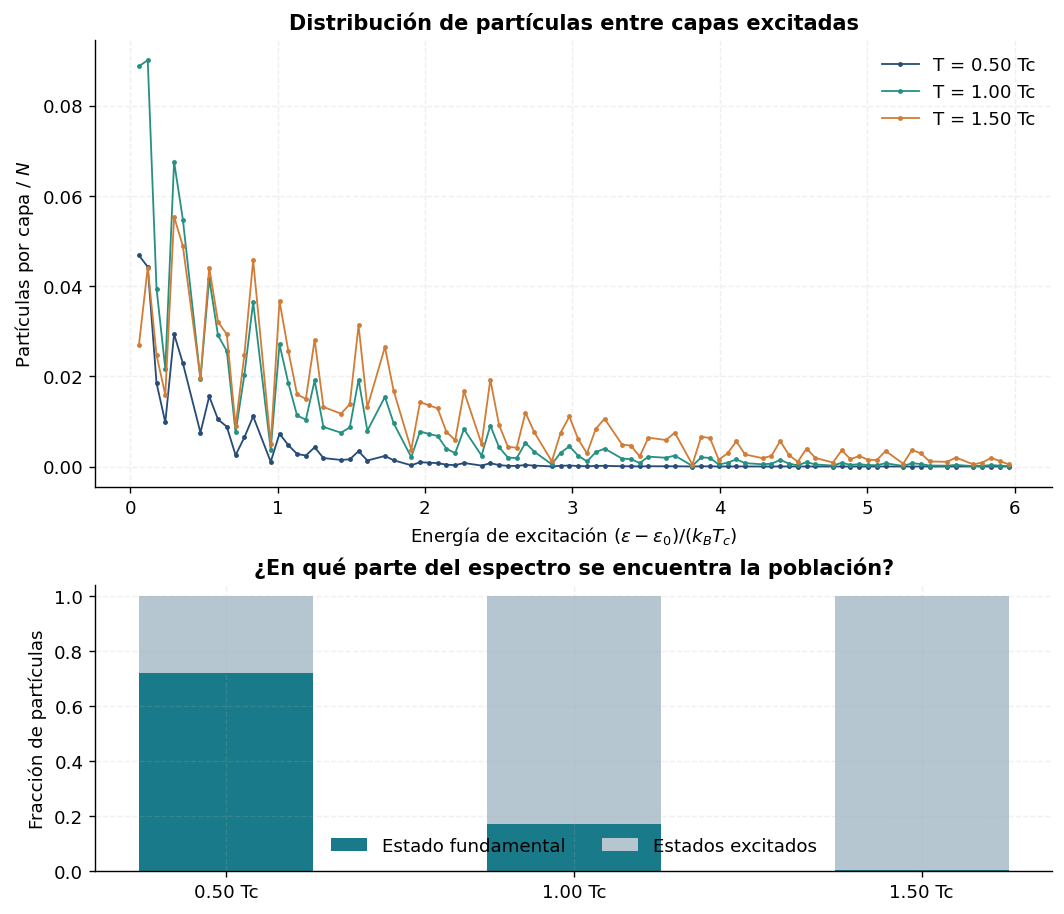

,T_Tc,N0_N,Nexc_N
0,0.5,0.72207,0.27793
1,1.0,0.17164,0.82836
2,1.5,0.00572,0.99428


In [13]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.4, 7.2), height_ratios=(1.25,0.8))
filas=[]
for t, nombre, color in [(0.50,'0.50 Tc',PALETA['baja']),
                          (1.00,'1.00 Tc',PALETA['media']),
                          (1.50,'1.50 Tc',PALETA['alta'])]:
    tau=t*kB*Tc_principal/EL_principal
    r=resolver_ocupaciones(N_PRINCIPAL, tau, u_main, g_main)
    E_red=u_main*EL_principal/(kB*Tc_principal)
    filtr=(E_red>0)&(E_red<6.0)
    ax1.plot(E_red[filtr], r['nivel'][filtr]/N_PRINCIPAL, '.-',
             ms=3.6, lw=1.05, color=color, label=f'T = {nombre}')
    filas.append({'T_Tc':t, 'N0_N':r['N0']/N_PRINCIPAL, 'Nexc_N':r['Nexc']/N_PRINCIPAL})
ax1.set_title('Distribución de partículas entre capas excitadas')
ax1.set_xlabel(r'Energía de excitación $(\varepsilon-\varepsilon_0)/(k_BT_c)$')
ax1.set_ylabel(r'Partículas por capa / $N$')
ax1.legend(loc='best')
valores=pd.DataFrame(filas)
ax2.bar(valores.T_Tc, valores.N0_N, width=0.25,
        label='Estado fundamental', color=PALETA['periodica'])
ax2.bar(valores.T_Tc, valores.Nexc_N, bottom=valores.N0_N,
        width=0.25, label='Estados excitados', color='#b6c6d0')
ax2.set_xticks([0.5,1.0,1.5], ['0.50 Tc','1.00 Tc','1.50 Tc'])
ax2.set_ylim(0,1.04)
ax2.set_ylabel('Fracción de partículas')
ax2.set_title('¿En qué parte del espectro se encuentra la población?')
ax2.legend(ncol=2, loc='lower center')
guardar('01_distribucion_energia.png')
display(valores.round(5))

**Lectura física:** al disminuir $T$, cada ocupación está controlada por el factor de Bose–Einstein. El balance completo implica que gran parte de la población migre al **único** estado fundamental, aunque las partículas excitadas sigan repartiéndose entre muchas capas. En particular, un pico de población por *capa* puede deberse también a una degeneración grande: no debe confundirse con una ocupación macroscópica de un único estado.

## 6. Emergencia del condensado y temperatura característica

Ahora repetimos la conservación para múltiples temperaturas. Sobreponemos, **solo al final**, la referencia del límite termodinámico:

$$
\frac{N_0}{N}\xrightarrow[N,V\to\infty]{N/V\,\mathrm{fijo}}
\begin{cases}1-(T/T_c)^{3/2},&T\leq T_c,\\0,&T>T_c,\end{cases}
$$

con $T_c=(2\pi\hbar^2/mk_B)\,[n/\zeta(3/2)]^{2/3}$. El valor de $T_c$ en el eje horizontal es **teórico**; para un número finito de partículas no existe una temperatura crítica no analítica. Como estimación **numérica de temperatura característica**, calculamos $T_{\rm sat}$, para la cual la población máxima de los **estados excitados**, evaluada en el límite $\mu\to\varepsilon_0^-$, iguala $N$:

$$\sum_{s>0}\frac{g_s}{\exp[(\varepsilon_s-\varepsilon_0)/(k_BT_{\rm sat})]-1}=N.$$

No se evalúa el fundamental en $\mu=\varepsilon_0$ (su ocupación divergiría). También localizamos, como segundo indicador, la **máxima pendiente** de la fracción simulada. En una caja finita ambos indicadores pueden diferir, precisamente porque **no existe una transición singular**.

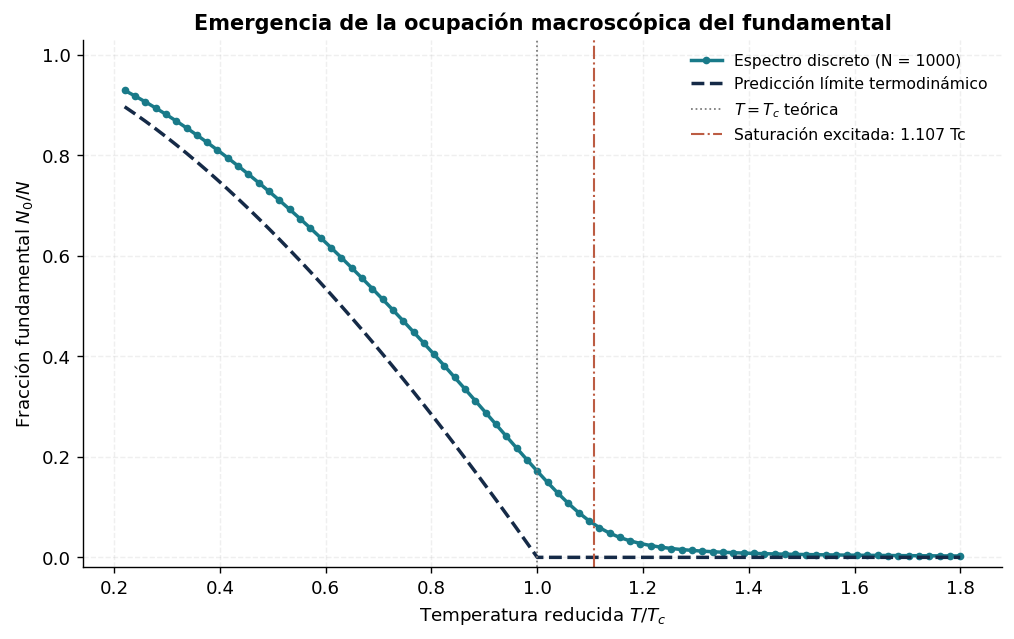

Indicador 1: saturación de excitaciones, T_sat/Tc = 1.1073
Indicador 2: máxima pendiente, T_pend/Tc = 0.9242
Ambos son indicadores operacionales diferentes para N finito, no una singularidad.


In [14]:
t_fino = np.linspace(0.60, 1.30, 150)
curva_fina,_ = curva_temperatura(N_PRINCIPAL, DENSIDAD_PRINCIPAL, t_fino)
pendiente = np.gradient(curva_fina.N0_N, curva_fina.T_Tc)
indice = int(np.argmin(pendiente))
t_caracteristica = float(curva_fina.T_Tc.iloc[indice])
T_sat_principal = temperatura_saturacion_exc(
    N_PRINCIPAL,DENSIDAD_PRINCIPAL,u_main,g_main)
t_sat_reducida = T_sat_principal/Tc_principal

fig, ax=plt.subplots()
ax.plot(curva_main.T_Tc, curva_main.N0_N, 'o-', ms=3.4,
        label=f'Espectro discreto (N = {N_PRINCIPAL})', color=PALETA['periodica'])
ax.plot(curva_main.T_Tc, fraccion_teorica(curva_main.T_Tc), '--',
        label='Predicción límite termodinámico',color=PALETA['teoria'])
ax.axvline(1.0, lw=1.0, color='#777777', ls=':',label=r'$T=T_c$ teórica')
ax.axvline(t_sat_reducida, lw=1.2, color=PALETA['rigida'], ls='-.',
           label=f'Saturación excitada: {t_sat_reducida:.3f} Tc')
ax.set(xlabel=r'Temperatura reducida $T/T_c$',
       ylabel=r'Fracción fundamental $N_0/N$', ylim=(-0.02,1.03),
       title='Emergencia de la ocupación macroscópica del fundamental')
ax.legend(loc='upper right', fontsize=9)
guardar('02_fraccion_condensada.png')
print(f'Indicador 1: saturación de excitaciones, T_sat/Tc = {t_sat_reducida:.4f}')
print(f'Indicador 2: máxima pendiente, T_pend/Tc = {t_caracteristica:.4f}')
print('Ambos son indicadores operacionales diferentes para N finito, no una singularidad.')

### 6.1. Potencial químico: señal complementaria

El potencial químico debe permanecer **por debajo** de la energía del nivel base. Su aproximación a $\varepsilon_0$ permite que $N_0=1/[e^{(\varepsilon_0-\mu)/(k_BT)}-1]$ crezca. En el límite termodinámico se dice que $\mu\to\varepsilon_0$ por debajo de $T_c$, pero **no** debemos fijar exactamente $\mu=\varepsilon_0$ en una suma discreta finita, pues la ocupación del nivel base divergiría.

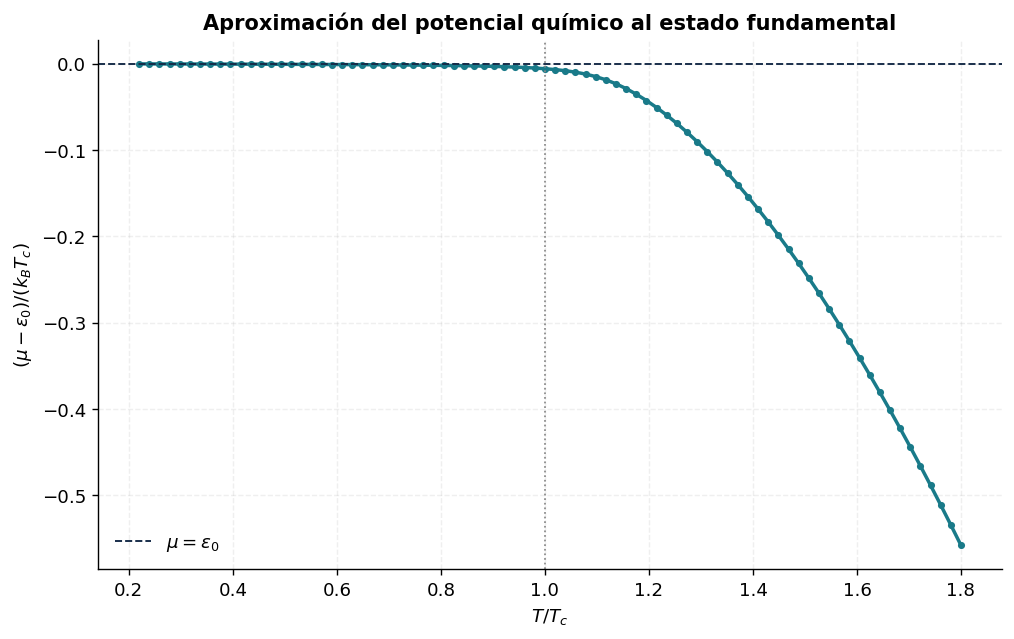

In [15]:
fig, ax=plt.subplots()
ax.plot(curva_main.T_Tc, curva_main.mu_menos_e0_sobre_kBTc,
        '-o', ms=3.1, color=PALETA['periodica'])
ax.axhline(0, color=PALETA['teoria'], lw=1.1, ls='--', label=r'$\mu=\varepsilon_0$')
ax.axvline(1, color='#888888', lw=1, ls=':')
ax.set(xlabel=r'$T/T_c$',ylabel=r'$(\mu-\varepsilon_0)/(k_BT_c)$',
       title='Aproximación del potencial químico al estado fundamental')
ax.legend()
guardar('03_potencial_quimico.png')

## 7. ¿Qué cambia al aumentar el número total de partículas?

Comparamos $N=250,1000,4000$ a **densidad fija**. La caja crece con $N$: $L=(N/n)^{1/3}$, y el espaciamiento entre niveles $E_L\propto L^{-2}$ disminuye. El límite termodinámico significa $N,V\to\infty$ con $n=N/V$ constante, **no** simplemente aumentar $N$ dentro del mismo volumen.

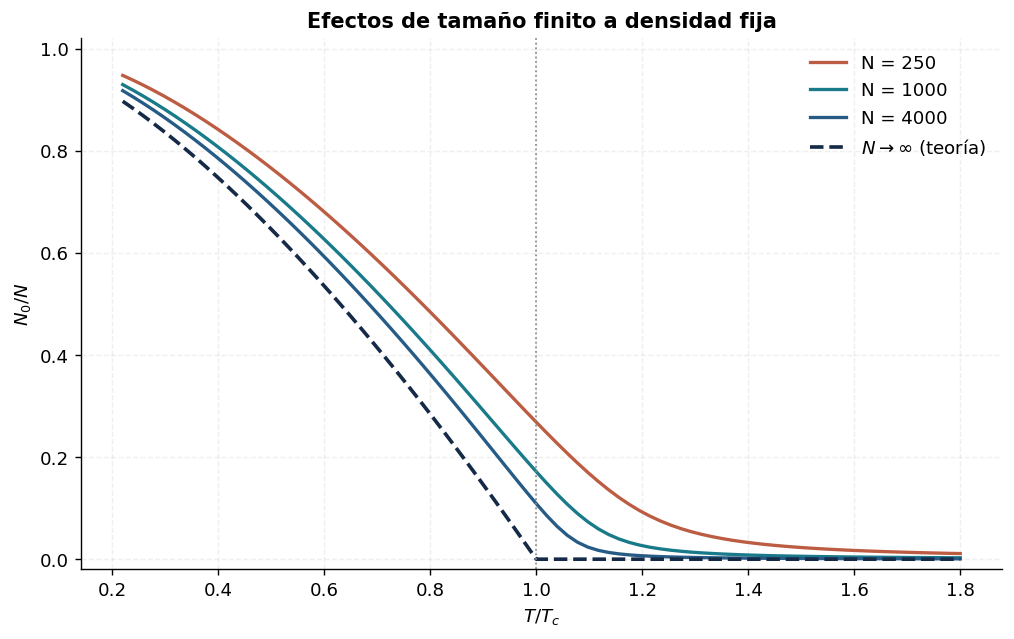

,N,N0_N_en_Tc,RMSE_vs_limite,Tsat_Tc
0,250,0.268553,0.132296,1.177398
1,1000,0.171645,0.079053,1.107258
2,4000,0.108992,0.047848,1.065800


In [16]:
Ns = [250,1000,4000]
curvas_N={}
fig, ax=plt.subplots()
for N_i,col in zip(Ns,['#bc5c43','#197a89','#265b86']):
    tabla,_ = curva_temperatura(N_i,DENSIDAD_PRINCIPAL,TEMPERATURAS_REDUCIDAS)
    curvas_N[N_i]=tabla
    ax.plot(tabla.T_Tc,tabla.N0_N,linewidth=1.9,label=f'N = {N_i}',color=col)
ax.plot(TEMPERATURAS_REDUCIDAS,fraccion_teorica(TEMPERATURAS_REDUCIDAS),
        '--',color=PALETA['teoria'],lw=2.1,label=r'$N\to\infty$ (teoría)')
ax.axvline(1, color='#888888',ls=':',lw=1)
ax.set(xlabel=r'$T/T_c$',ylabel=r'$N_0/N$',ylim=(-0.02,1.02),
       title='Efectos de tamaño finito a densidad fija')
ax.legend()
guardar('04_efecto_N.png')

# Indicadores cuantitativos a temperatura T=Tc
registros=[]
for N_i in Ns:
    rr=curvas_N[N_i]
    registros.append({'N':N_i, 'N0_N_en_Tc':np.interp(1,rr.T_Tc,rr.N0_N),
                      'RMSE_vs_limite':float(np.sqrt(np.mean(
                          (rr.N0_N-fraccion_teorica(rr.T_Tc))**2))),
                      'Tsat_Tc':float(temperatura_saturacion_exc(
                          N_i,DENSIDAD_PRINCIPAL,*espectro_caja(
                              float(rr.T_Tc.max()*kB*Tc_principal/energia_escala(N_i,DENSIDAD_PRINCIPAL)))
                          )/Tc_principal)})
tabla_tamanos=pd.DataFrame(registros)
display(tabla_tamanos.round(6))

**Interpretación:** la fórmula termodinámica muestra un cambio no analítico en el límite infinito. Para $N$ finito, la transición se **redondea**: puede existir una población del estado fundamental por encima de $T_c$ teórica, sin que eso implique una nueva fase termodinámica. La columna $T_{\rm sat}/T_c$ muestra cómo la temperatura característica extraída de las **sumas de niveles** se aproxima a 1 al crecer $N$. El error RMS del gráfico evalúa semejanza con la curva límite en el intervalo elegido: no es un error experimental ni una prueba de que el modelo finito sea incorrecto.

## 8. ¿Qué cambia al modificar la densidad?

El modelo predice $T_c\propto n^{2/3}$ para masa fija, de modo que una mayor densidad implica condensación a **mayor temperatura absoluta**. Para que esto sea evidente, aquí graficamos la misma fracción contra $T$ en **nanokelvin**, no contra $T/T_c$. Se conserva $N=1000$, y al variar $n$ cambia el volumen $V=N/n$.

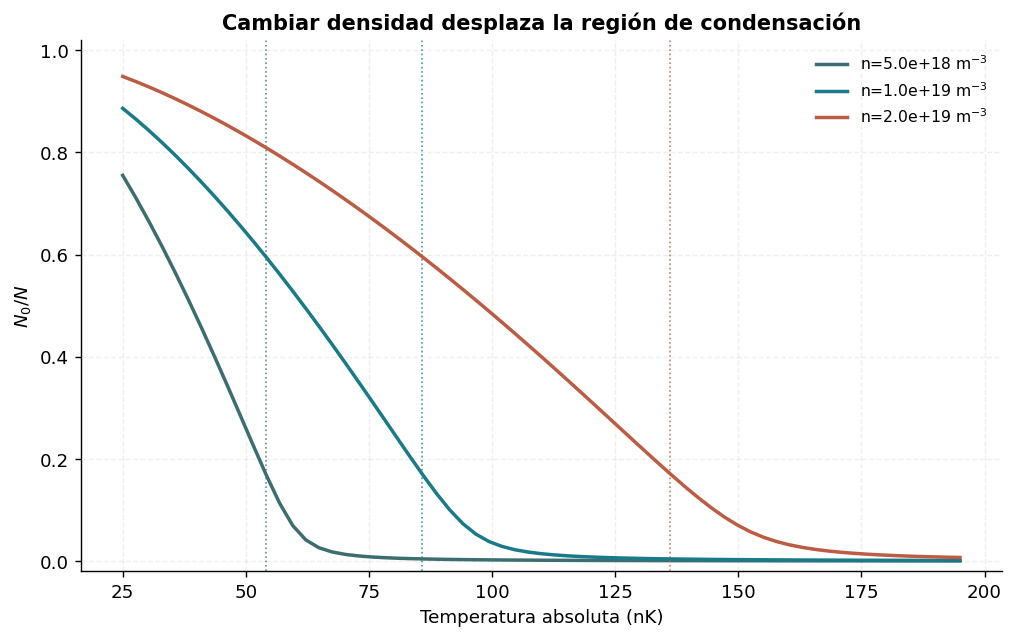

,densidad_m3,Tc_teorica_nK
0,5.000000e+18,54.005
1,1.000000e+19,85.728
2,2.000000e+19,136.085


In [17]:
densidades = [5e18,1e19,2e19]
T_abs_nK = np.linspace(25,195,65)
fig, ax=plt.subplots()
tabla_densidades=[]
for n_i,color in zip(densidades,['#3c6e71','#197a89','#bc5c43']):
    Tc_i=temperatura_critica_teorica(n_i)
    t_i=(T_abs_nK*1e-9)/Tc_i
    curva_i,_=curva_temperatura(N_PRINCIPAL,n_i,t_i)
    ax.plot(T_abs_nK,curva_i.N0_N,label=f'n={n_i:.1e} m$^{{-3}}$',color=color)
    ax.axvline(Tc_i*1e9,color=color,ls=':',lw=0.95,alpha=0.8)
    tabla_densidades.append({'densidad_m3':n_i,'Tc_teorica_nK':Tc_i*1e9})
ax.set(xlabel='Temperatura absoluta (nK)', ylabel=r'$N_0/N$',
       title='Cambiar densidad desplaza la región de condensación',ylim=(-.02,1.02))
ax.legend(fontsize=9)
guardar('05_efecto_densidad.png')
display(pd.DataFrame(tabla_densidades).round(3))

**Nota de interpretación:** los trazos punteados indican $T_c(n)$ del límite termodinámico. Al normalizar la temperatura por la $T_c$ de cada densidad, los resultados colapsan para el mismo $N$ y la misma geometría, ya que en esta caja ideal las energías escalan de manera uniforme con $L^{-2}$. La densidad modifica la escala de temperatura, no introduce por sí sola una interacción.

## 9. Pregunta original: ¿importan las condiciones de frontera?

Para estudiar el papel del confinamiento *sin introducir interacciones*, resolvemos el mismo problema con dos conjuntos de estados:

- **Periódicas:** $k_i=2\pi q_i/L$, $q_i\in\mathbb Z$, $\varepsilon_0=0$; espectro de excitación $u=\sum q_i^2$.
- **Paredes rígidas (Dirichlet):** $k_i=\pi q_i/L$, $q_i=1,2,\ldots$, $\varepsilon_0=3E_L/4$; excitaciones $u=(\sum q_i^2-3)/4$.

En ambos casos el fundamental es único. En las paredes rígidas el **potencial químico se mide respecto a su energía base propia**, por lo que se resuelve $\mu-\varepsilon_0$, no se identifica $\mu$ con el cero absoluto de energía.

La pregunta no es si la condensación desaparece: en una caja 3D macroscópica ambas condiciones comparten el mismo límite volumétrico. La pregunta es **cuánto influyen los niveles discretos y su degeneración cuando $N$ es pequeño**.

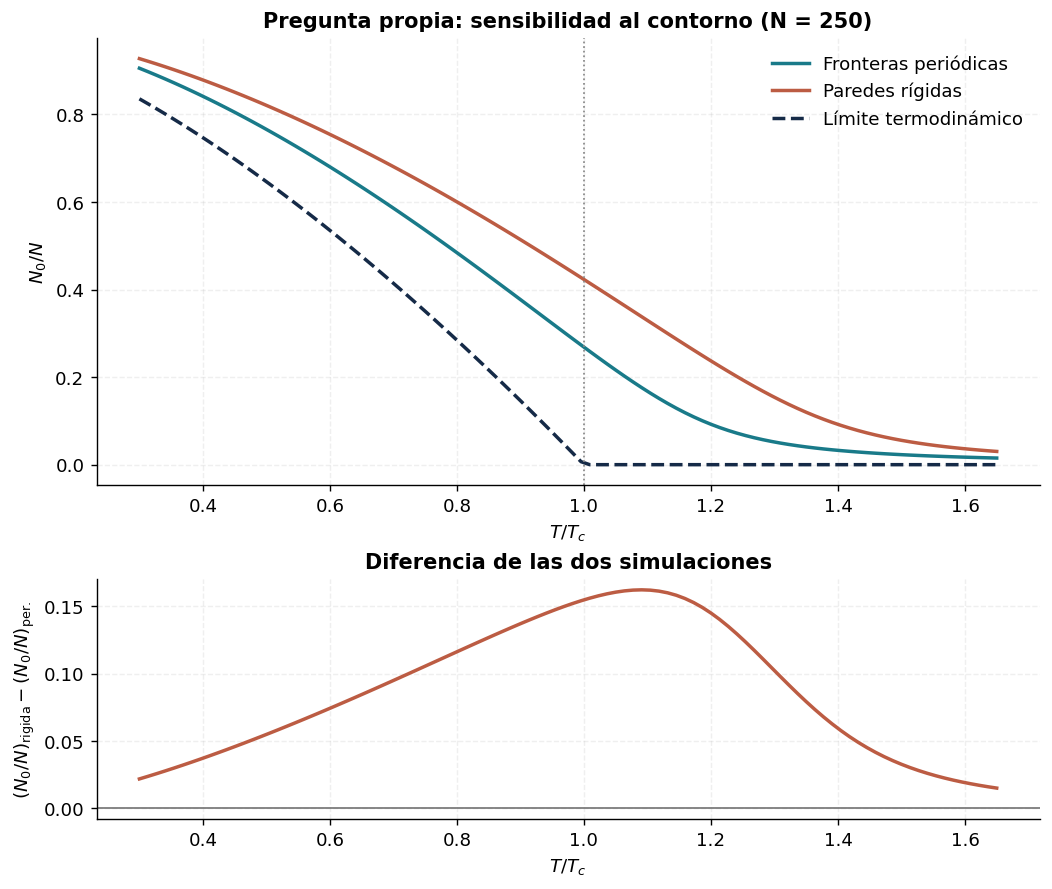

T/Tc=0.75: periódica=0.53591, rígida=0.64137, diferencia=+0.10546
T/Tc=1.00: periódica=0.26857, rígida=0.42312, diferencia=+0.15455
T/Tc=1.25: periódica=0.06833, rígida=0.19367, diferencia=+0.12534


In [18]:
N_frontera=250
t_frontera=np.linspace(0.30,1.65,100)
frontera_periodica,(u_p,g_p)=curva_temperatura(
    N_frontera,DENSIDAD_PRINCIPAL,t_frontera,'periodica')
frontera_rigida,(u_r,g_r)=curva_temperatura(
    N_frontera,DENSIDAD_PRINCIPAL,t_frontera,'rigida')

fig, (ax1,ax2)=plt.subplots(2,1,figsize=(8.3,7.0),height_ratios=[1.3,.7])
ax1.plot(t_frontera,frontera_periodica.N0_N, label='Fronteras periódicas',color=PALETA['periodica'])
ax1.plot(t_frontera,frontera_rigida.N0_N, label='Paredes rígidas',color=PALETA['rigida'])
ax1.plot(t_frontera,fraccion_teorica(t_frontera),'--',color=PALETA['teoria'],
         label='Límite termodinámico')
ax1.axvline(1,ls=':',color='#888888',lw=1)
ax1.set(xlabel=r'$T/T_c$',ylabel=r'$N_0/N$',
        title=f'Pregunta propia: sensibilidad al contorno (N = {N_frontera})')
ax1.legend()
ax2.plot(t_frontera,frontera_rigida.N0_N-frontera_periodica.N0_N,
         color=PALETA['rigida'])
ax2.axhline(0,color='#777777',lw=1)
ax2.set(xlabel=r'$T/T_c$',ylabel=r'$(N_0/N)_{\mathrm{rigida}}-(N_0/N)_{\mathrm{per.}}$',
        title='Diferencia de las dos simulaciones')
guardar('06_condiciones_frontera.png')

for tt in [0.75,1.0,1.25]:
    vp=float(np.interp(tt,t_frontera,frontera_periodica.N0_N))
    vr=float(np.interp(tt,t_frontera,frontera_rigida.N0_N))
    print(f'T/Tc={tt:.2f}: periódica={vp:.5f}, rígida={vr:.5f}, diferencia={vr-vp:+.5f}')

**Análisis físico:** las paredes modifican la separación y la degeneración de los niveles cuánticos. Como la ecuación de conservación depende de todos los $g_s$ y $u_s$, el reparto promedio de partículas cambia aun con la **misma** $N$, $V$ y $T$. Es un **efecto de tamaño finito**, no evidencia de que las fronteras cambien la ley universal del gas ideal homogéneo 3D en el límite termodinámico. La diferencia computada permite responder a la pregunta original, en lugar de responderla por intuición.

## 10. Resumen de resultados y comparación cuantitativa

Se presenta una tabla a temperaturas representativas para permitir una exposición con cifras concretas. En ella, la teoría se calcula **independientemente** del modelo discreto, como patrón de comparación.

In [19]:
filas_resumen=[]
for tt in [0.5,0.8,1.0,1.2,1.5]:
    tau=tt*kB*Tc_principal/EL_principal
    r=resolver_ocupaciones(N_PRINCIPAL,tau,u_main,g_main)
    sim=r['N0']/N_PRINCIPAL
    teo=float(fraccion_teorica(tt))
    filas_resumen.append({'T/Tc':tt,'N0/N (sim.)':sim,
                          'N0/N (teoría)':teo, 'Diferencia':sim-teo,
                          'Nexc/N':r['Nexc']/N_PRINCIPAL})
tabla_resumen=pd.DataFrame(filas_resumen)
display(tabla_resumen.round(5))
print(f'Tc ilustrativa: {Tc_principal*1e9:.2f} nK')
print(f'Máximo error |<N>-N| en barrido principal: {max(abs(curva_main.error_N)):.2e}')
print(f'Fronteras: máxima diferencia absoluta de N0/N: '
      f'{np.max(np.abs(frontera_rigida.N0_N-frontera_periodica.N0_N)):.5f}')
# Exportar tablas para comprobar resultados sin ejecutar nuevamente el cuaderno.
curva_main.to_csv('resultados_curva_principal.csv', index=False)
tabla_resumen.to_csv('resultados_resumen.csv', index=False)
tabla_convergencia.to_csv('resultados_convergencia.csv', index=False)

,T/Tc,N0/N (sim.),N0/N (teoría),Diferencia,Nexc/N
0,0.5,0.72207,0.64645,0.07562,0.27793
1,0.8,0.40979,0.28446,0.12534,0.59021
2,1.0,0.17164,0.00000,0.17164,0.82836
3,1.2,0.02644,0.00000,0.02644,0.97356
4,1.5,0.00572,0.00000,0.00572,0.99428


Tc ilustrativa: 85.73 nK
Máximo error |<N>-N| en barrido principal: 1.24e-08
Fronteras: máxima diferencia absoluta de N0/N: 0.16201


## 11. Conclusiones físicas

1. **La ocupación macroscópica surge del cómputo.** Al bajar $T$, la solución de la ecuación de conservación y las ocupaciones Bose–Einstein producen una transferencia notable de población al estado fundamental; la curva $1-(T/T_c)^{3/2}$ **no** se ha usado para generar estos resultados.
2. **$\mu$ es una variable de ajuste físico, no un parámetro libre de dibujo.** Debe acercarse a $\varepsilon_0$ para permitir muchas partículas en el fundamental y debe conservarse $\mu<\varepsilon_0$ para la suma finita.
3. **Los sistemas finitos tienen un cruce suave.** En una caja de $N$ finito existe alguna ocupación del fundamental incluso por encima de $T_c$ teórica. La temperatura de saturación de excitaciones $T_{\rm sat}$ es un indicador computacional que tiende hacia $T_c$ al aumentar $N$ a densidad fija, pero la transición singular solo se establece en el límite termodinámico.
4. **La densidad controla la escala térmica:** $T_c\propto n^{2/3}$ para masa fija; una comparación a temperatura absoluta hace visible el desplazamiento.
5. **El contorno modifica las correcciones finitas.** Al cambiar condiciones periódicas por paredes rígidas cambian energías y degeneraciones; por eso cambia la ocupación del fundamental aun sin interacciones.
6. **La validez numérica requiere verificar el corte.** Un espectro truncado prematuramente sobrestima el condensado, al omitir estados excitados disponibles.

### Limitaciones y alcance

- Se supone gas **ideal**, homogéneo y en equilibrio; no se simula una cámara experimental, colisiones, formación dinámica de condensado, detección de imágenes o un gas real atrapado.
- Se utiliza ocupación media en una descripción **gran canónica ajustada a $\langle N\rangle=N$**, no un muestreo canónico exacto de configuraciones con $N$ fijo. Las **fluctuaciones** del condensado requieren un tratamiento aparte.
- El potencial del gas con paredes rígidas difiere por un desplazamiento de energía del estado fundamental; se compara siempre $\mu-\varepsilon_0$.
- La temperatura de pendiente máxima es una convención para describir un cruce finito y puede cambiar con $N$, resolución en $T$ y condición de frontera.

## 12. Guía para sustentar el proyecto (preguntas habituales)

**¿Cuál es el problema físico?** Investigar si un gas de bosones no interactuantes acumula una cantidad macroscópica en el estado cuántico de menor energía cuando se enfría.

**¿Qué calcula exactamente el programa?** Los niveles discretos, su degeneración y sus **ocupaciones promedio**, imponiendo la conservación de $\langle N\rangle$ al resolver numéricamente el potencial químico para cada temperatura.

**¿Por qué no basta con graficar $1-(T/T_c)^{3/2}$?** Porque es justamente la predicción que se busca reproducir y contrastar. Aquí la fracción se calcula primero por suma de estados, y la curva límite se superpone después.

**¿Por qué no pongo $\mu=0$ en la simulación?** Con energía base cero, eso haría infinita la ocupación del fundamental: $N_0=[e^{-\beta\mu}-1]^{-1}$. Para una caja finita se necesita $\mu<0$; en el límite macroscópico puede tender a cero.

**¿Qué significa condensación?** Ocupación macroscópica de **un único estado**, no acumulación de partículas en una franja energética ancha ni condensación espacial de agua.

**¿Es una simulación Monte Carlo?** No. Es una simulación numérica determinista de ocupaciones estadísticas; esta estrategia está autorizada por el enunciado.

**¿Qué es $T_c$?** Una temperatura crítica definida exactamente en el límite termodinámico de un gas homogéneo 3D. En sistemas finitos se habla de un cruce suave: para estimarlo se puede calcular $T_{\rm sat}$ a partir de la capacidad máxima de los estados excitados (sin incluir el fundamental) y contrastar esa escala con el valor teórico.

**¿Qué aportó la pregunta propia?** Identificó hasta qué punto el resultado para $N$ finito depende de una elección no obvia del modelo: sus condiciones de frontera.

**¿Cómo se verificó que el código no fabrica condensación?** Se comprueba $\langle N\rangle=N$, el signo correcto de $\mu-\varepsilon_0$, el conteo del estado base y la independencia práctica frente a un corte energético más alto.

## 13. Bibliografía orientativa y trazabilidad de fuentes

**Fuente principal (documento suministrado):**  
Restrepo Cárdenas, J. (2026). *Física Estadística: Teoría, Algoritmos y Problemas*. Universidad de Antioquia. Especialmente **§4.10, pp. 146–154** (distribución Bose–Einstein, separación del estado base, función de Einstein) y **§6.6, pp. 204–214** (gas Bose ideal en $d$ dimensiones).

**Enunciado suministrado:**  
Restrepo C., J. (7 nov. 2026). *Miniproyecto #2 de Física Estadística 0302470*. Instituto de Física, Universidad de Antioquia.

**Fuentes complementarias — conviene verificar su pertinencia antes de incluirlas en el informe final:**

- Frankfurt, notas del curso *Ideal Bose gas*, cap. 14. https://itp.uni-frankfurt.de/~gros/Vorlesungen/TD/14_Ideal_Bose_gas.pdf (gas ideal homogéneo con fronteras periódicas).
- Dalfovo, F., Giorgini, S., Pitaevskii, L. P., & Stringari, S. (1999). *Theory of Bose–Einstein condensation in trapped gases*. *Reviews of Modern Physics*, **71**, 463–512. https://doi.org/10.1103/RevModPhys.71.463 (**contexto general de gases atrapados**, no idéntico a nuestra caja homogénea).
- Cheng, R., Wang, Q.-Y., Wang, Y.-L., & Zong, H.-S. (2021). *Finite-Size Effects with Boundary Conditions on Bose–Einstein Condensation*. *Symmetry*, **13**(2), 300. https://doi.org/10.3390/sym13020300 (antecedentes para la comparación de fronteras en tamaños finitos).

**Aporte del equipo:** elección del método discreto, implementación y comprobaciones de raíz, estudio de parámetros, comparación con el límite termodinámico y análisis adicional del contorno. Cualquier interpretación experimental de un gas real requiere hipótesis extra.